# 05 — Prédiction du Pb par Machine Learning (Random Forest, XGBoost, CatBoost)

## Objectif

Comparer le krigeage du notebook 04 aux trois modèles de Machine Learning pour estimer le **Pb**, à partir de X, Y, LandUse et RockType.

## Pourquoi comparer ML et Krigeage ?

Le krigeage exploite la **corrélation spatiale** (des points proches ont des valeurs proches). Le ML apprend une relation statistique entre les coordonnées X, Y, les variables catégorielles (LandUse, RockType) et le Pb. Bien qu'il utilise X et Y comme variables d'entrée, il ne dispose pas d'un cadre explicite de corrélation spatiale comme le krigeage, mais peut en revanche exploiter des covariables (LandUse, RockType) que le krigeage simple n'utilise pas. Comparer les deux permet de voir laquelle des deux logiques capture le mieux la réalité du terrain.

## Méthode en 2 étapes

1. **Sélection** : un split Train/Val/Test (70/15/15) et une validation croisée sur les 259 points permettent de désigner le meilleur algorithme (RF, XGBoost ou CatBoost).

2. **Modèle final** : le meilleur algorithme est réentraîné sur les **259 points complets**, puis testé sur les **100 points de `df_validation`**, c'est le même jeu que le krigeage.

Les deux méthodes sont évaluées avec le **même indicateur (RMSE)**, sur le **même jeu de 100 points**, car c'est une condition indispensable pour que la comparaison soit valide.

## Rappel : recréer le contexte (notebook 01)

**Pourquoi cette étape ?** Ce notebook doit pouvoir s'exécuter indépendamment des notebooks 02-04 (qui, eux, ont besoin de l'espace gaussien Y.Pb pour le krigeage). On recharge donc uniquement `data_jura`, la seule donnée nécessaire au Machine Learning.

In [114]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Ajout du chemin d'importation pour le module geostat_utils (remonte de jura/ jusqu'à src/)
sys.path.append(os.path.abspath(os.path.join("..", "..")))
import geostat_utils as gutils

# ---- Chargement des DEUX jeux de données dès le début ----
data_jura = gutils.charger_donnees_jura()
df_validation = pd.read_csv("../../../data/JuraValidationData.csv", sep=";")

print(f"Nombre de points d'entraînement (data_jura)   : {len(data_jura)}")
print(f"Nombre de points de validation (df_validation) : {len(df_validation)}")

# ---- Vérification que les colonnes correspondent bien entre les deux fichiers ----
print("\nColonnes data_jura      :", data_jura.columns.tolist())
print("Colonnes df_validation  :", df_validation.columns.tolist())

display(data_jura.head(3))
display(df_validation.head(3))

Nombre de points d'entraînement (data_jura)   : 259
Nombre de points de validation (df_validation) : 100

Colonnes data_jura      : ['X', 'Y', 'Landuse', 'RockType', 'Cd', 'Co', 'Cr', 'Cu', 'Ni', 'Pb', 'Zn']
Colonnes df_validation  : ['X', 'Y', 'Landuse', 'RockType', 'Cd', 'Co', 'Cr', 'Cu', 'Ni', 'Pb', 'Zn']


,X,Y,Landuse,RockType,Cd,Co,Cr,Cu,Ni,Pb,Zn
0,2.386,3.077,3,3,1.740,9.32,38.32,25.72,21.32,77.36,92.56
1,2.544,1.972,2,2,1.335,10.00,40.20,24.76,29.72,77.88,73.56
2,2.807,3.347,2,3,1.610,10.60,47.00,8.88,21.40,30.80,64.80


,X,Y,Landuse,RockType,Cd,Co,Cr,Cu,Ni,Pb,Zn
0,2.672,3.558,3,5,1.570,8.28,37.12,18.60,18.60,38.20,65.2
1,3.589,4.443,3,1,2.045,10.80,40.80,11.48,21.52,33.36,112.8
2,4.010,4.713,2,1,1.203,12.00,53.20,13.04,23.92,26.56,91.6


## 1. Préparation des features et de la cible

**Pourquoi pas besoin de l'anamorphose gaussienne (Y.Pb) ici ?** Les modèles à base d'arbres (Random Forest, XGBoost, CatBoost) ne font aucune hypothèse de distribution. On travaille donc directement sur **Pb** à l'échelle réelle (mg/kg), sans passer par le Normal Score du notebook 02.

**Pourquoi encoder LandUse et RockType en one-hot ?** Ce sont des **codes catégoriels**, pas des quantités : RockType=4 n'est pas « deux fois plus » que RockType=2. L'encodage one-hot crée une colonne binaire (0/1) par modalité, ce qui neutralise ce faux ordre numérique.

In [115]:
"""
Préparation des features et de la cible pour le Machine Learning.
Sépare les variables numériques (X, Y) et catégorielles (Landuse, RockType),
convertit ces dernières en texte pour l'encodage one-hot, et extrait les
tableaux finaux X_ml (features) et Pb_ml (cible), en valeurs réelles (mg/kg).
"""
features_Coord = ["X", "Y"]
features_cat = ["Landuse", "RockType"]
features_ml  = features_Coord + features_cat
cible_ml     = "Pb"

data_jura[features_cat] = data_jura[features_cat].astype(int).astype(str)

X_ml  = data_jura[features_ml]
Pb_ml = data_jura[cible_ml]

print(f"Features utilisées : {features_ml}")
print(f"Cible               : {cible_ml} (échelle réelle, mg/kg)")
print(f"Nombre total de points disponibles : {len(X_ml)}")

Features utilisées : ['X', 'Y', 'Landuse', 'RockType']
Cible               : Pb (échelle réelle, mg/kg)
Nombre total de points disponibles : 259


## 2. Split Train / Validation / Test (70 / 15 / 15) pour choisir le meilleur algorithme

**Important :** ce split ne sert **qu'à comparer objectivement** Random Forest, XGBoost et CatBoost entre eux (partie 4 plus bas). Le modèle finalement utilisé pour l'estimation sur `df_validation` sera réentraîné sur les 259 points complets (partie 5). Ce split n'est donc qu'une étape intermédiaire de sélection, et non la version finale du modèle.

In [116]:
"""
Split Train / Validation / Test (70 / 15 / 15).
Découpage en deux temps : d'abord Train (70%) vs Temp (30%), puis Temp
est redécoupé en deux parts égales pour obtenir Validation (15%) et
Test (15%). Sert uniquement à comparer les algorithmes ML entre eux ;
le modèle final sera réentraîné sur l'ensemble des 259 points.
"""
X_train_ml, X_temp_ml, Pb_train, Pb_temp = train_test_split(X_ml, Pb_ml, test_size=0.30, random_state=42)
X_val_ml,   X_test_ml, Pb_val,   Pb_test = train_test_split(X_temp_ml, Pb_temp, test_size=0.50, random_state=42)

print(f"Train      : {len(X_train_ml):,} points")
print(f"Validation : {len(X_val_ml):,} points")
print(f"Test       : {len(X_test_ml):,} points")

Train      : 181 points
Validation : 39 points
Test       : 39 points


## 3. Fonctions de métriques et validation croisée (K-Fold)

**Pourquoi la validation croisée (K-Fold, K=5) ?** Avec seulement 259 points, un seul découpage Train/Test peut donner un résultat trompeur selon le hasard du tirage. La validation croisée découpe le Train en 5 parts, entraîne 5 fois le modèle, puis moyenne les 5 scores obtenus. Cela donne une estimation plus stable qu'un score unique, et permet aussi de repérer un éventuel surapprentissage.

**Pourquoi plusieurs métriques (R², RMSE, MAE, SMAPE) ?** Chacune capture un aspect différent de l'erreur : R² (variance expliquée), RMSE (pénalise les grosses erreurs), MAE (erreur typique, robuste aux valeurs extrêmes), SMAPE (erreur relative en %).

### Formules

$$
R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}
\qquad
\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^n |y_i - \hat{y}_i|
$$

$$
\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n (y_i - \hat{y}_i)^2}
\qquad
\mathrm{SMAPE} = \frac{100\%}{n}\sum_{i=1}^n \frac{|y_i - \hat{y}_i|}{(|y_i| + |\hat{y}_i|)/2}
$$

Définitions reprises de Chicco, Warrens & Jurman (*"The coefficient of determination R-squared is more informative than SMAPE, MAE, MAPE, MSE and RMSE in regression analysis evaluation"*) pour R², MAE et SMAPE ; RMSE suit la même définition que dans le notebook 04 (Chai & Draxler).

In [117]:
"""
Fonctions de métriques et de visualisation pour l'évaluation des modèles ML.

Définit la stratégie de validation croisée (K-Fold à 5 plis), les métriques
de régression utilisées (R², RMSE, MAE, SMAPE), ainsi que deux fonctions
d'affichage : un résumé texte des métriques par split (Train/Val/Test), et
un graphique de comparaison valeurs réelles vs estimées.
"""

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

def calcul_rmse(y_reel, y_estime):
    """Même formule que dans le notebook 04 (rmse_ok, rmse_sk)."""
    return np.sqrt(np.nanmean((np.asarray(y_estime) - np.asarray(y_reel)) ** 2))

def smape(y_reel, y_estime):
    """Erreur absolue en pourcentage symétrique (SMAPE), en %."""
    return 100 * np.mean(2 * np.abs(y_estime - y_reel) / (np.abs(y_reel) + np.abs(y_estime) + 1e-8))

def afficher_metriques_split(Pb_train, Pb_train_pred, Pb_val, Pb_val_pred, Pb_test, Pb_test_pred, nom_modele=""):
    """Affiche R², RMSE, MAE et SMAPE pour les jeux Train, Validation et Test."""
    splits = [("Train", Pb_train, Pb_train_pred), ("Validation", Pb_val, Pb_val_pred), ("Test", Pb_test, Pb_test_pred)]
    print(f"\n=== {nom_modele} ===")
    for nom_split, y_reel, y_estime in splits:
        print(f"{nom_split}:")
        print(f"  R²    : {r2_score(y_reel, y_estime):.4f}")
        print(f"  RMSE  : {calcul_rmse(y_reel, y_estime):.4f}")
        print(f"  MAE   : {mean_absolute_error(y_reel, y_estime):.4f}")
        print(f"  SMAPE : {smape(y_reel, y_estime):.2f}%")
    print("-" * 35)

def afficher_estim_vs_reel(y_reel, y_estime, nom_modele, split="Validation"):
    """Trace le nuage de points valeurs réelles vs estimées, avec la ligne de prédiction parfaite."""
    r2 = r2_score(y_reel, y_estime)
    plt.figure(figsize=(6, 6))
    plt.scatter(y_reel, y_estime, alpha=0.5, edgecolor="k", s=15, color="steelblue")
    vmin, vmax = min(y_reel.min(), y_estime.min()), max(y_reel.max(), y_estime.max())
    plt.plot([vmin, vmax], [vmin, vmax], "r--", label="Ligne parfaite")
    plt.xlabel("Pb réel (mg/kg)")
    plt.ylabel("Pb estimé (mg/kg)")
    plt.title(f"{split} — {nom_modele}  R²={r2:.3f}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

print("Fonctions de métriques chargées")

Fonctions de métriques chargées


## 4. Préprocesseur commun

**Pourquoi standardiser X, Y (StandardScaler) alors que les modèles à base d'arbres n'en ont pas strictement besoin ?** Par bonne pratique et cohérence de pipeline — cela ne nuit pas aux performances des 3 modèles utilisés ici.

**Pourquoi le `ColumnTransformer` ?** Il applique un traitement différent selon le type de variable (StandardScaler pour X, Y ; OneHotEncoder pour Landuse, RockType) dans un seul objet réutilisable.

In [118]:
# ---- Préprocesseur : standardisation des coordonnées (X, Y) + one-hot encoding des variables catégorielles (Landuse, RockType) ----
preprocesseur_ml = ColumnTransformer([
    ("num", StandardScaler(), features_Coord),
    ("cat", OneHotEncoder(handle_unknown="ignore"), features_cat)
])

## 5. Random Forest — entraînement de sélection (sur le Train, 70%)

**Principe :** construit un grand nombre d'arbres de décision, chacun entraîné sur un échantillon aléatoire des données (bootstrap). La prédiction finale est la moyenne des prédictions de tous les arbres, ce qui réduit la variance par rapport à un arbre unique.

CV R² moyen Random Forest : 0.0977

=== Random Forest — Pb (Train 70%) ===
Train:
  R²    : 0.5524
  RMSE  : 19.7982
  MAE   : 11.6182
  SMAPE : 19.51%
Validation:
  R²    : 0.0837
  RMSE  : 23.4625
  MAE   : 18.5278
  SMAPE : 34.46%
Test:
  R²    : 0.5013
  RMSE  : 24.3378
  MAE   : 17.3028
  SMAPE : 30.12%
-----------------------------------


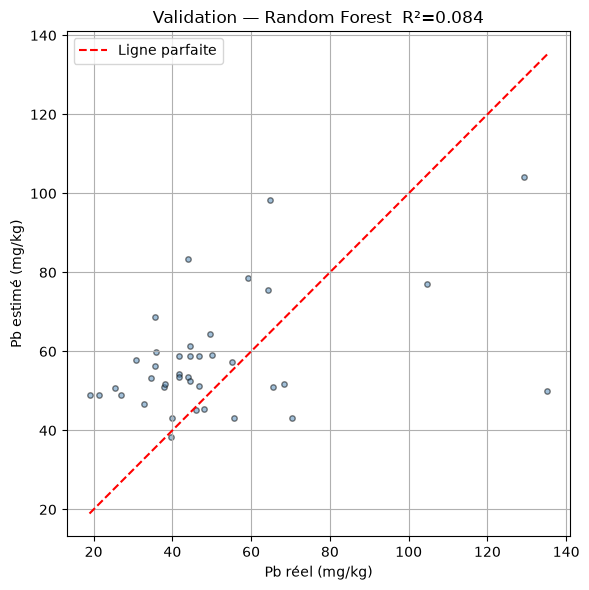

In [119]:
"""
Random Forest — entraînement de sélection (sur le Train, 70%).
Configure le pipeline (prétraitement + RandomForestRegressor), évalue sa
performance moyenne par validation croisée 5-fold sur le Train, puis
entraîne le modèle final et affiche ses métriques et son graphique
réel vs estimé sur les jeux Train, Validation et Test.
"""
rf_params = {
    "n_estimators"     : 200,
    "max_depth"        : 10,
    "min_samples_split": 5,
    "min_samples_leaf" : 2,
    "max_features"     : "sqrt",
    "bootstrap"        : True,
    "random_state"     : 42,
    "n_jobs"           : -1
}
pipe_rf = Pipeline([("prep", preprocesseur_ml), ("model", RandomForestRegressor(**rf_params))])

cv_rf = cross_validate(pipe_rf, X_train_ml, Pb_train, cv=cv, scoring=scoring)
print("CV R² moyen Random Forest :", np.mean(cv_rf["test_r2"]).round(4))

pipe_rf.fit(X_train_ml, Pb_train)
Pb_train_pred_rf = pipe_rf.predict(X_train_ml)
Pb_val_pred_rf   = pipe_rf.predict(X_val_ml)
Pb_test_pred_rf  = pipe_rf.predict(X_test_ml)

afficher_metriques_split(Pb_train, Pb_train_pred_rf, Pb_val, Pb_val_pred_rf, Pb_test, Pb_test_pred_rf, nom_modele="Random Forest — Pb (Train 70%)")
afficher_estim_vs_reel(Pb_val, Pb_val_pred_rf, "Random Forest")

## 6. XGBoost — entraînement de sélection (sur le Train, 70%)

**Principe :** contrairement au Random Forest, XGBoost construit ses arbres **séquentiellement** : chaque nouvel arbre corrige les erreurs des précédents (boosting de gradient).

CV R² moyen XGBoost : -0.001

=== XGBoost — Pb (Train 70%) ===
Train:
  R²    : 0.9969
  RMSE  : 1.6439
  MAE   : 1.2295
  SMAPE : 2.50%
Validation:
  R²    : 0.2253
  RMSE  : 21.5747
  MAE   : 15.5531
  SMAPE : 27.69%
Test:
  R²    : 0.6513
  RMSE  : 20.3514
  MAE   : 13.8884
  SMAPE : 24.47%
-----------------------------------


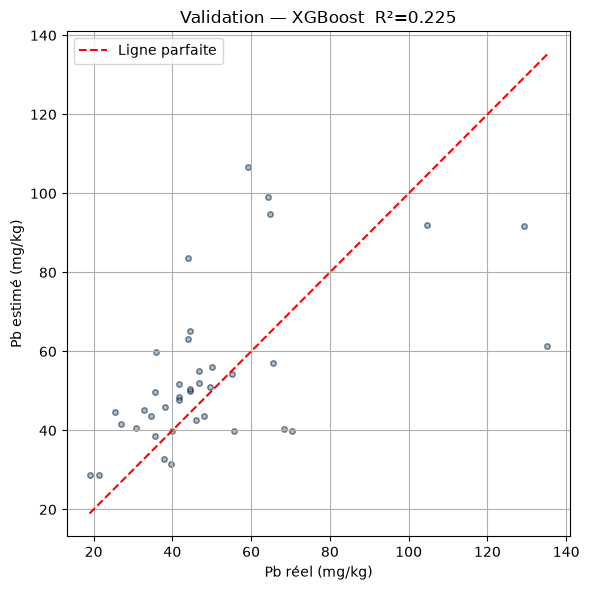

In [120]:
"""
XGBoost — entraînement de sélection (sur le Train, 70%).

Configure le pipeline (prétraitement + XGBRegressor), évalue sa performance
moyenne par validation croisée 5-fold sur le Train, puis entraîne le modèle
final et affiche ses métriques et son graphique réel vs estimé sur les jeux
Train, Validation et Test.
"""
xgb_params = {
    "n_estimators"    : 300,
    "max_depth"       : 6,
    "learning_rate"   : 0.05,
    "subsample"       : 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda"      : 1.0,
    "reg_alpha"       : 0.1,
    "gamma"           : 0.0,
    "random_state"    : 42,
    "tree_method"     : "hist",
    "objective"       : "reg:squarederror",
    "verbosity"       : 0
}
pipe_xgb = Pipeline([("prep", preprocesseur_ml), ("model", XGBRegressor(**xgb_params))])

cv_xgb = cross_validate(pipe_xgb, X_train_ml, Pb_train, cv=cv, scoring=scoring)
print("CV R² moyen XGBoost :", np.mean(cv_xgb["test_r2"]).round(4))

pipe_xgb.fit(X_train_ml, Pb_train)
Pb_train_pred_xgb = pipe_xgb.predict(X_train_ml)
Pb_val_pred_xgb   = pipe_xgb.predict(X_val_ml)
Pb_test_pred_xgb  = pipe_xgb.predict(X_test_ml)

afficher_metriques_split(Pb_train, Pb_train_pred_xgb, Pb_val, Pb_val_pred_xgb, Pb_test, Pb_test_pred_xgb, nom_modele="XGBoost — Pb (Train 70%)")
afficher_estim_vs_reel(Pb_val, Pb_val_pred_xgb, "XGBoost")

**Observation — surapprentissage détecté :** R²=0.997 sur le Train, mais R² négatif (-0.001) en validation croisée — XGBoost mémorise le bruit plutôt que d'apprendre une vraie tendance, avec seulement 181 points d'entraînement.

## 7. CatBoost — entraînement de sélection (sur le Train, 70%)

**Principe :** même famille que XGBoost (boosting de gradient séquentiel), avec une gestion native des variables catégorielles souvent plus robuste, demandant moins de réglage manuel.

CV R² moyen CatBoost : 0.0838

=== CatBoost — Pb (Train 70%) ===
Train:
  R²    : 0.9287
  RMSE  : 7.9020
  MAE   : 6.0183
  SMAPE : 11.52%
Validation:
  R²    : 0.2557
  RMSE  : 21.1464
  MAE   : 15.2018
  SMAPE : 27.97%
Test:
  R²    : 0.5663
  RMSE  : 22.6957
  MAE   : 17.2769
  SMAPE : 29.67%
-----------------------------------


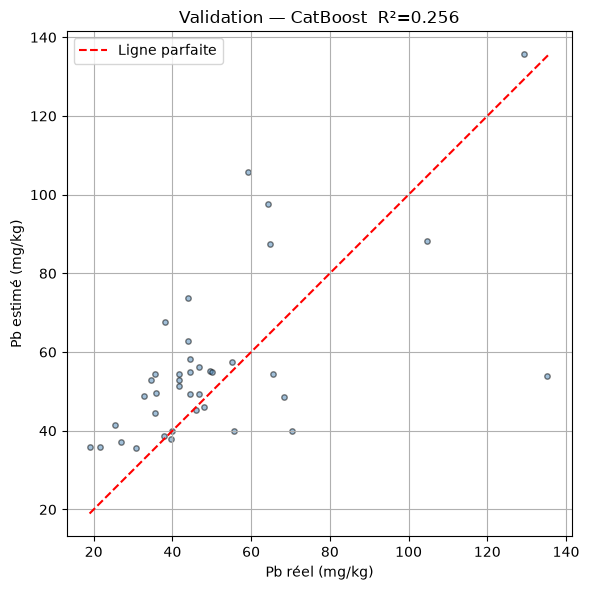

In [121]:
"""
CatBoost — entraînement de sélection (sur le Train, 70%).

Configure le pipeline (prétraitement + CatBoostRegressor), évalue sa
performance moyenne par validation croisée 5-fold sur le Train, puis
entraîne le modèle final et affiche ses métriques et son graphique
réel vs estimé sur les jeux Train, Validation et Test.
"""
cat_params = {
    "iterations"     : 200,
    "depth"          : 6,
    "learning_rate"  : 0.1,
    "l2_leaf_reg"    : 3.0,
    "subsample"      : 0.8,
    "random_strength": 0.3,
    "random_state"   : 42,
    "loss_function"  : "RMSE",
    "verbose"        : False
}
pipe_cat = Pipeline([("prep", preprocesseur_ml), ("model", CatBoostRegressor(**cat_params))])

cv_cat = cross_validate(pipe_cat, X_train_ml, Pb_train, cv=cv, scoring=scoring)
print("CV R² moyen CatBoost :", np.mean(cv_cat["test_r2"]).round(4))

pipe_cat.fit(X_train_ml, Pb_train)
Pb_train_pred_cat = pipe_cat.predict(X_train_ml)
Pb_val_pred_cat   = pipe_cat.predict(X_val_ml)
Pb_test_pred_cat  = pipe_cat.predict(X_test_ml)

afficher_metriques_split(Pb_train, Pb_train_pred_cat, Pb_val, Pb_val_pred_cat, Pb_test, Pb_test_pred_cat, nom_modele="CatBoost — Pb (Train 70%)")
afficher_estim_vs_reel(Pb_val, Pb_val_pred_cat, "CatBoost")

## 8. Comparaison des 3 modèles — désignation du meilleur algorithme
**Pourquoi comparer sur le R² de validation croisée, pas sur le Test ?** Le Test ne doit servir qu'à l'évaluation finale du modèle déjà choisi (section 10). L'utiliser pour sélectionner le modèle introduirait un biais optimiste. On compare donc les 3 algorithmes sur leur **R² moyen en validation croisée (CV)**, plus robuste avec seulement 259 points (moyenne sur 5 découpages indépendants). Le modèle avec le meilleur CV R² est celui dont l'**algorithme** (pas les poids déjà appris) sera réentraîné sur les 259 points complets à l'étape suivante.

In [122]:
"""
Comparaison des 3 modèles — désignation du meilleur algorithme.

Compare Random Forest, XGBoost et CatBoost sur leur R² moyen en validation
croisée (CV), la métrique la plus robuste pour la sélection (contrairement
au Test, réservé à l'évaluation finale). Affiche aussi les métriques sur
Test à titre indicatif, puis désigne l'algorithme au meilleur CV R² comme
candidat pour le réentraînement final sur les 259 points complets.
"""
cv_r2_par_modele = {
    "Random Forest": np.mean(cv_rf["test_r2"]),
    "XGBoost"      : np.mean(cv_xgb["test_r2"]),
    "CatBoost"     : np.mean(cv_cat["test_r2"]),
}

modeles_ml = {
    "Random Forest": Pb_test_pred_rf,
    "XGBoost"      : Pb_test_pred_xgb,
    "CatBoost"     : Pb_test_pred_cat,
}

print("=" * 70)
print(f"{'Modèle':<16} {'CV R² (sélection)':>18} {'Test R²':>16}")
print("=" * 70)
for nom in modeles_ml:
    print(f"{nom:<16} {cv_r2_par_modele[nom]:>18.4f} {r2_score(Pb_test, modeles_ml[nom]):>16.4f}")
print("=" * 70)

meilleur_modele_cv = max(cv_r2_par_modele, key=cv_r2_par_modele.get)
print(f"\nMeilleur algorithme selon le CV R² (indicatif) : {meilleur_modele_cv}")
print("Les 3 modèles seront tout de même réentraînés (partie 9) — la décision finale se fera sur df_validation (partie 12).")

Modèle            CV R² (sélection)          Test R²
Random Forest                0.0977           0.5013
XGBoost                     -0.0010           0.6513
CatBoost                     0.0838           0.5663

Meilleur algorithme selon le CV R² (indicatif) : Random Forest
Les 3 modèles seront tout de même réentraînés (partie 9) — la décision finale se fera sur df_validation (partie 12).


## 9. Réentraînement des 3 modèles sur les 259 points complets

**Pourquoi réentraîner maintenant sur 100% de `data_jura`, et pas garder les modèles entraînés sur le Train (70%) ?** Une fois les 3 algorithmes comparés équitablement en validation croisée (partie 8), ce dernier a rempli son rôle de sélection ; il n'y a plus de raison de priver le modèle final des 30% d'exemples mis de côté jusqu'ici. On réentraîne donc chacun des 3 pipelines sur l'intégralité des 259 points avant l'estimation finale sur `df_validation`.

Ces 3 modèles réentraînés portent le suffixe `_full` pour bien les distinguer des modèles de sélection entraînés uniquement sur le Train (70%).

In [123]:
"""
Réentraîne les 3 modèles (RF, XGBoost, CatBoost) sur les 259 points
complets. Les métriques ici sont indicatives (points déjà vus, score
optimiste) — seule l'évaluation sur df_validation (partie 10) reflète
la vraie performance et désignera le vainqueur final (partie 12).
"""
pipe_rf_full  = Pipeline([("prep", preprocesseur_ml), ("model", RandomForestRegressor(**rf_params))])
pipe_xgb_full = Pipeline([("prep", preprocesseur_ml), ("model", XGBRegressor(**xgb_params))])
pipe_cat_full = Pipeline([("prep", preprocesseur_ml), ("model", CatBoostRegressor(**cat_params))])

pipe_rf_full.fit(X_ml, Pb_ml)
pipe_xgb_full.fit(X_ml, Pb_ml)
pipe_cat_full.fit(X_ml, Pb_ml)

for nom, pipe_full in [("Random Forest", pipe_rf_full), ("XGBoost", pipe_xgb_full), ("CatBoost", pipe_cat_full)]:
    Pb_pred_full = pipe_full.predict(X_ml)
    print(f"\n=== {nom} — 259 points (entraînement complet) ===")
    print(f"  R²    : {r2_score(Pb_ml, Pb_pred_full):.4f}")
    print(f"  RMSE  : {calcul_rmse(Pb_ml, Pb_pred_full):.4f}")
    print(f"  MAE   : {mean_absolute_error(Pb_ml, Pb_pred_full):.4f}")

print("\nLes 3 modèles ont été réentraînés sur les 259 points complets.")


=== Random Forest — 259 points (entraînement complet) ===
  R²    : 0.6715
  RMSE  : 17.0423
  MAE   : 10.7425

=== XGBoost — 259 points (entraînement complet) ===
  R²    : 0.9943
  RMSE  : 2.2473
  MAE   : 1.6420

=== CatBoost — 259 points (entraînement complet) ===
  R²    : 0.9102
  RMSE  : 8.9114
  MAE   : 6.6792

Les 3 modèles ont été réentraînés sur les 259 points complets.


## 10. Estimation finale sur `df_validation` (100 points)

**Pourquoi ce jeu précisément ?** `df_validation` est un jeu **structurellement indépendant** de `data_jura` — ces 100 points n'ont jamais fait partie de l'entraînement, quelle que soit la version du modèle (70% ou 100%). C'est surtout **exactement le même jeu de 100 points** que celui utilisé pour évaluer le krigeage (notebook 04) : condition indispensable pour une comparaison ML vs krigeage non biaisée.

**Quel modèle utilise-t-on ici ?** Les 3 modèles `_full` (réentraînés sur les 259 points), afin de comparer leurs performances respectives sur `df_validation` avant de désigner, en toute fin de notebook, le meilleur algorithme global.

In [124]:
df_validation = pd.read_csv("../../../data/JuraValidationData.csv", sep=";")
df_validation[features_cat] = df_validation[features_cat].astype(int).astype(str)

Pb_pred_rf_valid  = pipe_rf_full.predict(df_validation[features_ml])
Pb_pred_xgb_valid = pipe_xgb_full.predict(df_validation[features_ml])
Pb_pred_cat_valid = pipe_cat_full.predict(df_validation[features_ml])

vraie_pb = df_validation["Pb"].to_numpy()   # même variable que dans le notebook 04 (krigeage)

rmse_rf  = calcul_rmse(vraie_pb, Pb_pred_rf_valid)
rmse_xgb = calcul_rmse(vraie_pb, Pb_pred_xgb_valid)
rmse_cat = calcul_rmse(vraie_pb, Pb_pred_cat_valid)

print(f"RMSE Random Forest (df_validation) : {rmse_rf:.3f}")
print(f"RMSE XGBoost (df_validation)       : {rmse_xgb:.3f}")
print(f"RMSE CatBoost (df_validation)      : {rmse_cat:.3f}")

RMSE Random Forest (df_validation) : 41.102
RMSE XGBoost (df_validation)       : 41.935
RMSE CatBoost (df_validation)      : 42.636


## 11. Complément du tableau `df_resultats` (notebook 05)

**Pourquoi fusionner dans le même tableau que le krigeage ?** Pour que toutes les méthodes (SK, OK,
Random Forest, XGBoost, CatBoost) soient visibles côte à côte, point par point, dans un seul DataFrame.

In [125]:
resultats_krigeage = gutils.charger_resultats_krigeage()

df_resultats = pd.DataFrame({
    "X": df_validation["X"],
    "Y": df_validation["Y"],
    "Pb_reel": vraie_pb,
})
if resultats_krigeage:
    df_resultats["Pb_OK"] = resultats_krigeage["pred_ok_pb"]
    df_resultats["Pb_SK"] = resultats_krigeage["pred_sk_pb"]

df_resultats["Pb_RandomForest"] = Pb_pred_rf_valid
df_resultats["Pb_XGBoost"]      = Pb_pred_xgb_valid
df_resultats["Pb_CatBoost"]     = Pb_pred_cat_valid

display(df_resultats.head(100))

,X,Y,Pb_reel,Pb_OK,Pb_SK,Pb_RandomForest,Pb_XGBoost,Pb_CatBoost
0,2.672,3.558,38.20,37.253299,37.205465,53.775049,73.464867,61.794327
1,3.589,4.443,33.36,43.121759,42.976929,39.965777,48.416595,42.498065
2,4.010,4.713,26.56,44.472873,43.823685,38.043101,43.923435,45.008619
3,2.942,3.137,25.88,39.242939,39.015432,49.951141,65.324059,40.542856
4,1.409,2.748,31.16,46.642017,45.925671,55.071721,59.853600,55.561457
...,...,...,...,...,...,...,...,...
95,4.248,2.489,48.80,47.369204,47.116855,51.458050,50.458523,54.174612
96,3.784,3.677,34.32,52.621425,52.425431,51.752879,44.041950,56.338447
97,4.324,2.835,60.00,54.748938,54.171131,49.377938,44.516632,48.436881
98,3.859,4.022,60.80,55.306320,55.110657,51.709641,45.952435,57.212059


## 12. Comparaison finale (Krigeage vs Machine Learning)

**Pourquoi cette dernière étape est le vrai livrable du PFE :** les deux approches méthodologiques sont
confrontées sur un pied d'égalité, avec le même critère (RMSE), sur le même jeu de validation externe
de 100 points, chacune utilisant **toute l'information disponible** de son côté (259 points pour le ML,
259 points aussi pour le krigeage/variogramme).

Si `rmse_ok` et `rmse_sk` sont déjà en mémoire (notebook 04 exécuté avant), ils sont récupérés automatiquement

In [126]:
df_validation = pd.read_csv("../../../data/JuraValidationData.csv", sep=";")
df_validation[features_cat] = df_validation[features_cat].astype(int).astype(str)

Pb_pred_rf_valid  = pipe_rf_full.predict(df_validation[features_ml])
Pb_pred_xgb_valid = pipe_xgb_full.predict(df_validation[features_ml])
Pb_pred_cat_valid = pipe_cat_full.predict(df_validation[features_ml])

vraie_pb = df_validation["Pb"].to_numpy()   # même variable que dans le notebook 04 (krigeage)

rmse_rf  = calcul_rmse(vraie_pb, Pb_pred_rf_valid)
rmse_xgb = calcul_rmse(vraie_pb, Pb_pred_xgb_valid)
rmse_cat = calcul_rmse(vraie_pb, Pb_pred_cat_valid)

print(f"RMSE Random Forest (df_validation) : {rmse_rf:.3f}")
print(f"RMSE XGBoost (df_validation)       : {rmse_xgb:.3f}")
print(f"RMSE CatBoost (df_validation)      : {rmse_cat:.3f}")

# ---- Modèle final retenu : celui avec le RMSE le plus bas sur df_validation (la vraie décision finale) ----
pipes_full = {"Random Forest": pipe_rf_full, "XGBoost": pipe_xgb_full, "CatBoost": pipe_cat_full}
rmse_par_modele = {"Random Forest": rmse_rf, "XGBoost": rmse_xgb, "CatBoost": rmse_cat}

MODEL_NAME = min(rmse_par_modele, key=rmse_par_modele.get)
BEST_MODEL = pipes_full[MODEL_NAME]
print(f"\nModèle final retenu pour la comparaison avec le krigeage : {MODEL_NAME} (RMSE={rmse_par_modele[MODEL_NAME]:.3f})")

RMSE Random Forest (df_validation) : 41.102
RMSE XGBoost (df_validation)       : 41.935
RMSE CatBoost (df_validation)      : 42.636

Modèle final retenu pour la comparaison avec le krigeage : Random Forest (RMSE=41.102)


## Conclusion

Trois algorithmes de Machine Learning (Random Forest, XGBoost, CatBoost) ont été comparés via un split Train/Validation/Test (70/15/15) et une validation croisée K-Fold sur les 259 points de `data_jura`, puis tous réentraînés sur l'intégralité des 259 points et évalués sur `df_validation` (100 points) — le même jeu que celui utilisé pour le krigeage (notebook 04).

**Résultat** : le krigeage ordinaire obtient le RMSE le plus bas (**38.858**), devant Random Forest (**41.102**, meilleur des 3 modèles ML), XGBoost (41.935) et CatBoost (42.636). Sur ce jeu de données, le krigeage géostatistique généralise donc mieux que le Machine Learning, malgré l'accès de ce dernier à des covariables supplémentaires (LandUse, RockType).